<a href="https://colab.research.google.com/github/HeyWinTomsy/MN/blob/main/%D0%9B%D0%A07_%D0%90%D0%BD%D1%82%D1%80%D0%BE%D0%BF%D0%BE%D0%B2_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [2]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape
print("Перші рядки датасету:")
display(df.head())

Перші рядки датасету:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [34]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
print("\nПропущені значення:")
print(df.isnull().sum())
print("\nКількість дублікатів:")
print(df.duplicated().sum())


Пропущені значення:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів:
0


In [7]:
# TODO: виведіть описову статистику
# Підказка: describe()
print("\nОписова статистика:")
display(df.describe())


Описова статистика:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [8]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
# Відокремлення ознак та цільової змінної
X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)

print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір X_train: (1870, 13)
Розмір X_test: (468, 13)
Розмір y_train: (1870,)
Розмір y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [9]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
# Підрахунок кількості кожного класу
print("Кількість об'єктів кожного класу:")
print(y_train.value_counts())

print("\nВідсоткове співвідношення:")
print(y_train.value_counts(normalize=True) * 100)


Кількість об'єктів кожного класу:
Cured
0    946
1    924
Name: count, dtype: int64

Відсоткове співвідношення:
Cured
0    50.588235
1    49.411765
Name: proportion, dtype: float64


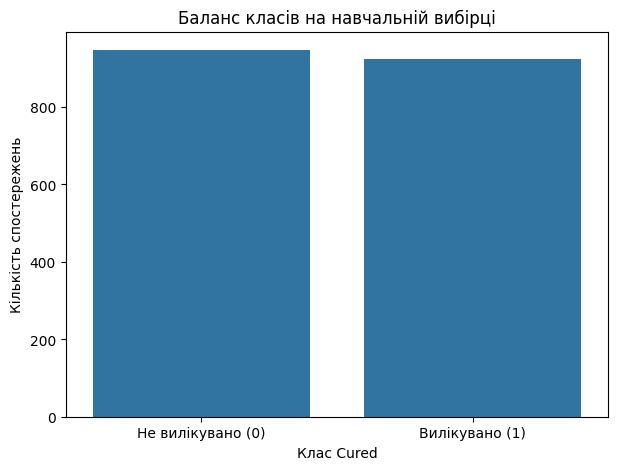

In [10]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)
plt.figure(figsize=(7, 5))

sns.countplot(x=y_train)

plt.title("Баланс класів на навчальній вибірці")
plt.xlabel("Клас Cured")
plt.ylabel("Кількість спостережень")
plt.xticks([0, 1], ['Не вилікувано (0)', 'Вилікувано (1)'])

plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

Як видно кількість тих хто вилікуаний та не ввилікуваний відносно однаковий. Як би одне значення було би дуже більше за інше, це могло би вплинути на точність моделі бо вона частіше буде передбачати той клас, якого було більше

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

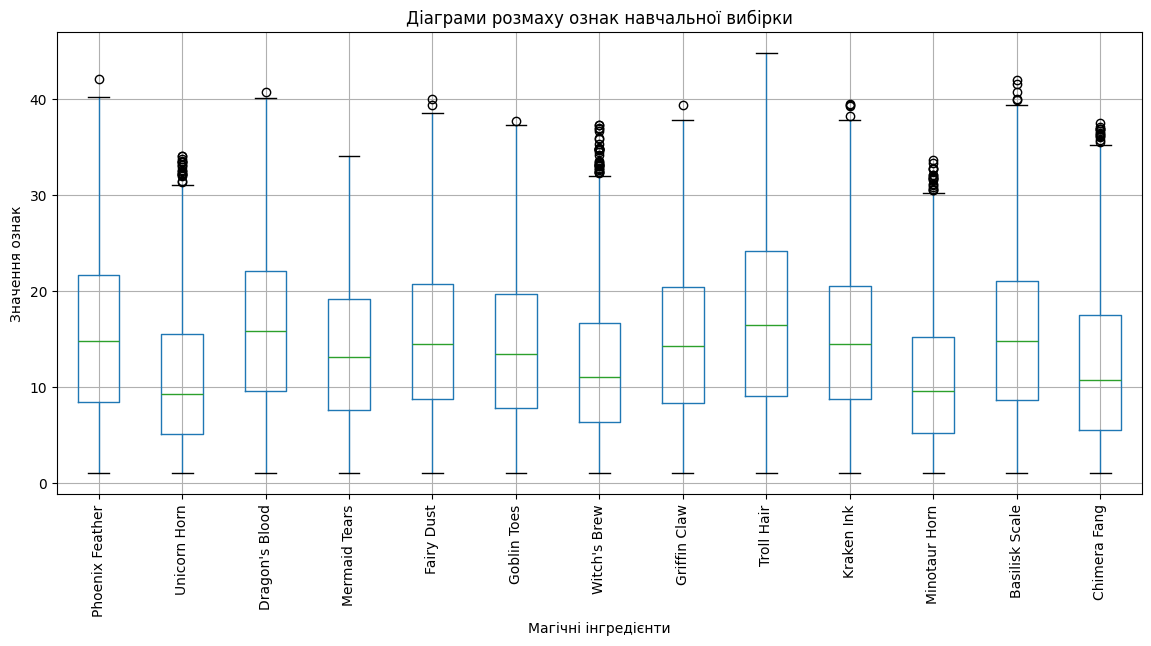

In [11]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
plt.figure(figsize=(14, 6))

X_train.boxplot(rot=90)

plt.title("Діаграми розмаху ознак навчальної вибірки")
plt.ylabel("Значення ознак")
plt.xlabel("Магічні інгредієнти")

plt.show()

In [12]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = (
    (X_train < lower_bound) |
    (X_train > upper_bound)
).sum()

outliers = outliers.sort_values(ascending=False)

print("Кількість потенційних викидів у кожній ознаці:")
display(outliers.to_frame(name="Кількість викидів"))

Кількість потенційних викидів у кожній ознаці:


,Кількість викидів
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


**Висновок про викиди:**  
У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?

Найбільша кулькість викидів покаазана у таблиці вище. Видаляти їх не вварто бо їхнє видалення може вплинути на якість моделі

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

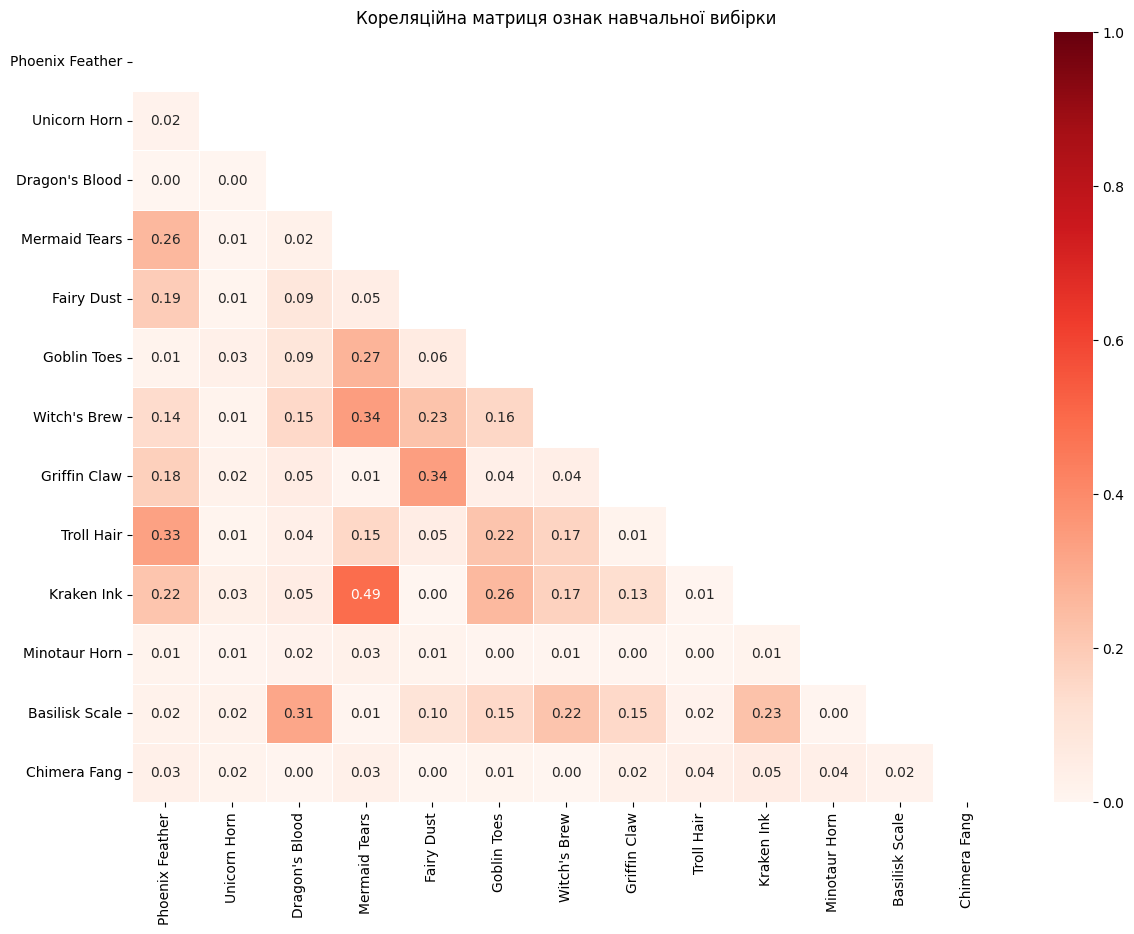

In [13]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
# Матриця абсолютних значень кореляцій
mtx = X_train.corr().abs()

mask = np.triu(
    np.ones_like(mtx, dtype=bool)
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    cmap='Reds',
    vmin=0,
    vmax=1,
    fmt='.2f',
    linewidths=0.5
)

plt.title("Кореляційна матриця ознак навчальної вибірки")
plt.show()

In [14]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
train_corr = pd.concat(
    [X_train, y_train],
    axis=1
).corr()

target_corr = train_corr['Cured'].drop('Cured')

target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

print("Кореляція ознак із Cured:")
display(target_corr.to_frame(name="Кореляція з Cured"))

Кореляція ознак із Cured:


,Кореляція з Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

як видно найвища кореляція з вилікувваними є з волосям троля

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [15]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
# Створення об'єкта стандартизації
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Розмір стандартизованої навчальної вибірки:",
      X_train_scaled.shape)

print("Розмір стандартизованої тестової вибірки:",
      X_test_scaled.shape)

Розмір стандартизованої навчальної вибірки: (1870, 13)
Розмір стандартизованої тестової вибірки: (468, 13)


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [16]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
model = LogisticRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

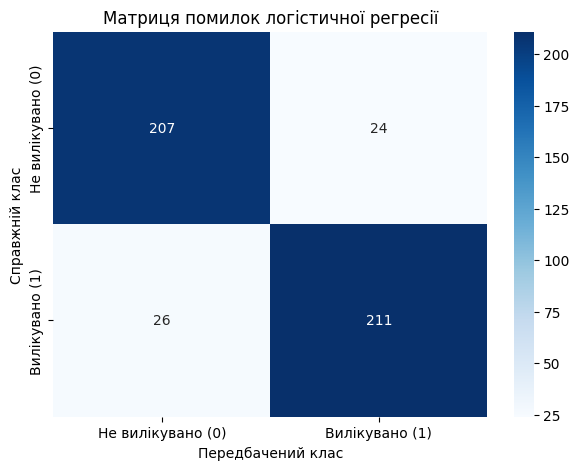

In [17]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    conf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не вилікувано (0)', 'Вилікувано (1)'],
    yticklabels=['Не вилікувано (0)', 'Вилікувано (1)']
)

plt.title("Матриця помилок логістичної регресії")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")

plt.show()

In [20]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
results = pd.DataFrame({
    'Справжній клас': y_test,
    'Передбачений клас': y_pred
})

display(results.sample(10, random_state=42))

,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

Як видно помилок не так багато. Все ж більше помилок де передбачалося не вилікувано, а ніспрадві вилікуано (26)


### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [24]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500, 1000]
}

param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500, 1000, 1500]
}

In [25]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid_search = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри GridSearchCV:")
print(grid_search.best_params_)

print("\nНайкраща Accuracy на крос-валідації:")
print(grid_search.best_score_)

Найкращі параметри GridSearchCV:
{'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}

Найкраща Accuracy на крос-валідації:
0.8673927508197171


In [26]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
random_search = RandomizedSearchCV(
    LogisticRegression(),
    param_dist,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри RandomizedSearchCV:")
print(random_search.best_params_)

print("\nНайкраща Accuracy на крос-валідації:")
print(random_search.best_score_)

Найкращі параметри RandomizedSearchCV:
{'solver': 'liblinear', 'max_iter': 500, 'C': 10}

Найкраща Accuracy на крос-валідації:
0.8673927508197171


In [27]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
print("GridSearchCV:", grid_search.best_score_)
print("RandomizedSearchCV:", random_search.best_score_)

if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
    best_method = "GridSearchCV"
else:
    best_model = random_search.best_estimator_
    best_method = "RandomizedSearchCV"

print("\nОбраний метод:", best_method)

print("Найкращі параметри:")
print(best_model.get_params())

y_pred_best = best_model.predict(X_test_scaled)

best_accuracy = accuracy_score(y_test, y_pred_best)

print("\nAccuracy оптимізованої моделі:", best_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

GridSearchCV: 0.8673927508197171
RandomizedSearchCV: 0.8673927508197171

Обраний метод: GridSearchCV
Найкращі параметри:
{'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Accuracy оптимізованої моделі: 0.8931623931623932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



In [28]:
comparison = pd.DataFrame({
    'Модель': [
        'Базова логістична регресія',
        'Оптимізована логістична регресія'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_best)
    ],
    'F1-score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_best)
    ]
})

display(comparison)

,Модель,Accuracy,F1-score
0,Базова логістична регресія,0.893162,0.894068
1,Оптимізована логістична регресія,0.893162,0.894068


### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [29]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
log_model = best_model

svm_model = SVC()

tree_model = DecisionTreeClassifier(random_state=42)

models = {
    'Logistic Regression': log_model,
    'SVM': svm_model,
    'Decision Tree': tree_model
}

In [30]:
model_results = []

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    model_results.append({
        'Модель': name,
        'Accuracy': accuracy,
        'F1-score': f1
    })

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1-score',
    ascending=False
)

display(results_df)

,Модель,Accuracy,F1-score
1,SVM,0.959402,0.960000
0,Logistic Regression,0.893162,0.894068
2,Decision Tree,0.865385,0.865672


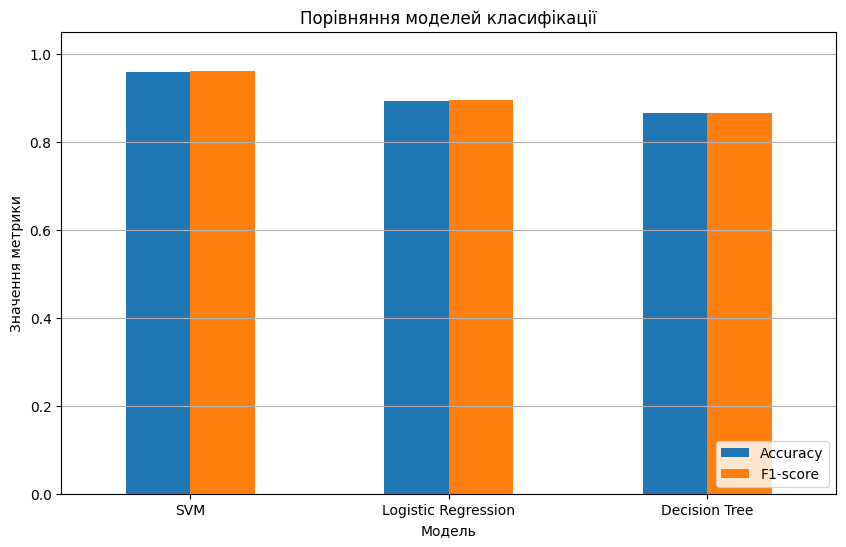

In [31]:
results_df.set_index('Модель')[
    ['Accuracy', 'F1-score']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Порівняння моделей класифікації")
plt.ylabel("Значення метрики")
plt.xlabel("Модель")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')

plt.show()

In [33]:
best_result = results_df.iloc[0]

print("Найкраща модель:", best_result['Модель'])
print("Accuracy:", best_result['Accuracy'])
print("F1-score:", best_result['F1-score'])

Найкраща модель: SVM
Accuracy: 0.9594017094017094
F1-score: 0.96


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.